# Advantage Actor-Critic (A2C) on Acrobot

In QAC the actor was driven by the critic's action value $\hat q(s_t, a_t; w)$. Advantage Actor-Critic (A2C) improves this with a **baseline**. The policy gradient does not change if a function $b(s)$ of the state alone is subtracted:

$$\mathbb{E}\big[\nabla_\theta \ln \pi(A \mid S;\theta)\, q_\pi(S, A)\big]
= \mathbb{E}\big[\nabla_\theta \ln \pi(A \mid S;\theta)\, \big(q_\pi(S, A) - b(S)\big)\big].$$

The baseline does not change the expected gradient, but it can greatly reduce its **variance**. A simple and good choice is the state value, $b(s) = v_\pi(s)$, which gives the **advantage function**

$$\delta_\pi(s, a) = q_\pi(s, a) - v_\pi(s).$$

Since $v_\pi(s)$ is the average of $q_\pi(s, a)$ under the policy, $\delta_\pi(s, a) > 0$ means that action $a$ is better than average. Finally, the advantage is approximated by the **TD error**,

$$q_\pi(s_t, a_t) - v_\pi(s_t) \approx r_{t+1} + \gamma\, v_\pi(s_{t+1}) - v_\pi(s_t),$$

so a single critic network $\hat v(s; w)$ is enough; no action-value network is needed.

At time step $t$ of each episode:

1. Generate $a_t$ following $\pi(a \mid s_t;\theta_t)$ and then observe $r_{t+1}, s_{t+1}$.
2. **Advantage (TD error):**
$$\delta_t = r_{t+1} + \gamma\, \hat v(s_{t+1}; w_t) - \hat v(s_t; w_t).$$
3. **Actor** (policy update):
$$\theta_{t+1} = \theta_t + \alpha_\theta\, \delta_t\, \nabla_\theta \ln \pi(a_t \mid s_t;\theta_t).$$
4. **Critic** (value update):
$$w_{t+1} = w_t + \alpha_w\, \delta_t\, \nabla_w \hat v(s_t; w_t).$$

Because the advantage is estimated with the TD error, the algorithm is also called **TD actor-critic**. As in QAC, both networks are updated at every time step, the stochastic policy provides the exploration, and there is no replay buffer or target network.

In [1]:
import gymnasium as gym
import numpy as np
import random
import time

import torch
import torch.nn as nn
from matplotlib import pyplot as plt

## Configuration

The actor and the critic have separate parameters, $\theta$ and $w$, and therefore separate learning rates, $\alpha_\theta$ and $\alpha_w$.

In [2]:
# Training configuration
NUM_EPISODES = 500
MAX_STEPS_PER_EPISODE = 500
GAMMA = 0.99
ACTOR_LEARNING_RATE = 0.0001  # alpha_theta (policy)
CRITIC_LEARNING_RATE = 0.001  # alpha_w (value function)
HIDDEN_SIZE = 128

SEED = 42

## Environment

`Acrobot-v1` is a chain of two links hanging from a fixed joint. Only the joint *between* the two links has a motor. The goal is to swing the free end of the lower link above a target height.

The six observations are:

1. $\cos\theta_1$;
2. $\sin\theta_1$;
3. $\cos\theta_2$;
4. $\sin\theta_2$;
5. angular velocity $\dot\theta_1$;
6. angular velocity $\dot\theta_2$,

where $\theta_1$ is the angle of the first link measured from the downward vertical and $\theta_2$ is the angle of the second link relative to the first.

There are three actions: `0`, `1` and `2` apply a torque of $-1$, $0$ and $+1$ to the actuated joint. The agent receives reward $-1$ at every step. The episode terminates (with reward $0$) when the height of the free end,

$$h = -\cos\theta_1 - \cos(\theta_1 + \theta_2),$$

exceeds $1$, and it is truncated after 500 steps. The return is therefore approximately minus the number of steps needed to reach the goal ($-500$ if it is never reached). Gymnasium considers an average return of $-100$ to be solved.

The motor is too weak to lift the links directly: the agent has to learn to swing back and forth to pump energy into the system.

In [3]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

env = gym.make(
    "Acrobot-v1",
    max_episode_steps=MAX_STEPS_PER_EPISODE,
)
env.action_space.seed(SEED)
env.observation_space.seed(SEED)

state_size = env.observation_space.shape[0]
action_size = env.action_space.n

print("State size:", state_size)
print("Action size:", action_size)
print("Maximum episode steps:", env.spec.max_episode_steps)
print("Reward threshold:", env.spec.reward_threshold)
print("Device:", device)

State size: 6
Action size: 3
Maximum episode steps: 500
Reward threshold: -100.0
Device: cpu


## Actor: policy network

The actor is the same network used for REINFORCE. It receives the six observations and returns three **logits**, one for each torque:

$$[\cos\theta_1, \sin\theta_1, \cos\theta_2, \sin\theta_2, \dot\theta_1, \dot\theta_2]\;\longrightarrow\;[z_{-1}, z_{0}, z_{+1}].$$

A softmax converts the logits into the action probabilities $\pi(a \mid s;\theta)$. As before, the softmax is left to PyTorch's categorical distribution.

In [4]:
class PolicyNetwork(nn.Module):
    """Map an Acrobot observation to one logit per action."""

    def __init__(self, state_size, action_size, hidden_size):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, action_size),
        )

    def forward(self, state):
        return self.net(state)

## Critic: state-value network

The critic now estimates the state value, so it returns a single number for each observation:

$$s \;\longrightarrow\; \hat v(s; w).$$

The last dimension of size one is removed so that a batch of states gives a vector of values.

In [5]:
class ValueNetwork(nn.Module):
    """Map an Acrobot observation to its state value."""

    def __init__(self, state_size, hidden_size):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, 1),
        )

    def forward(self, state):
        return self.net(state).squeeze(-1)

In [6]:
actor_net = PolicyNetwork(state_size, action_size, HIDDEN_SIZE).to(device)
critic_net = ValueNetwork(state_size, HIDDEN_SIZE).to(device)

# theta and w are updated by two optimizers with their own step sizes.
actor_optimizer = torch.optim.Adam(actor_net.parameters(), lr=ACTOR_LEARNING_RATE)
critic_optimizer = torch.optim.Adam(critic_net.parameters(), lr=CRITIC_LEARNING_RATE)

## Policy helpers

These are the helpers of REINFORCE. During training, the agent samples from the policy, and the log-probability of the sampled action is kept for the actor update. In A2C the action $a_t$ is sampled and used in the same time step, so it can be returned together with its log-probability. During evaluation, the greedy action is the action with the largest logit.

In [7]:
def state_to_tensor(state):
    """Convert one observation into a batch containing one state."""
    return torch.as_tensor(
        state, dtype=torch.float32, device=device
    ).unsqueeze(0)


def sample_action(state):
    """Sample an action and return its log-probability."""
    logits = actor_net(state_to_tensor(state))
    distribution = torch.distributions.Categorical(logits=logits)
    action_tensor = distribution.sample()
    log_probability = distribution.log_prob(action_tensor).squeeze()

    action = int(action_tensor.item())
    return action, log_probability


def greedy_action(state):
    """Choose the action with the largest policy logit."""
    with torch.no_grad():
        logits = actor_net(state_to_tensor(state))

    return int(logits.argmax(dim=1).item())

### Check the network outputs

For each observation, the actor returns three logits and therefore three probabilities that sum to one. The critic returns one state value.

In [8]:
example_states = torch.zeros((4, state_size), device=device)
example_logits = actor_net(example_states)
example_probabilities = torch.softmax(example_logits, dim=1)
example_values = critic_net(example_states)

print("Observations:        ", tuple(example_states.shape))
print("Policy logits:       ", tuple(example_logits.shape))
print("Action probabilities:", tuple(example_probabilities.shape))
print("Probability sums:    ", example_probabilities.sum(dim=1))
print("Critic state values: ", tuple(example_values.shape))

Observations:         (4, 6)
Policy logits:        (4, 3)
Action probabilities: (4, 3)
Probability sums:     tensor([1., 1., 1., 1.], grad_fn=<SumBackward1>)
Critic state values:  (4,)


## Actor and critic updates

For one transition $(s_t, a_t, r_{t+1}, s_{t+1})$ we first calculate the TD target and the TD error,

$$y_t =
\begin{cases}
r_{t+1}, & \text{if } s_{t+1} \text{ is terminal}, \\
r_{t+1} + \gamma\, \hat v(s_{t+1}; w_t), & \text{otherwise,}
\end{cases}
\qquad
\delta_t = y_t - \hat v(s_t; w),$$

and then minimize two losses.

**Actor.**

$$L_{\text{actor}}(\theta) = -\,\delta_t\, \ln \pi(a_t \mid s_t;\theta),
\qquad
-\nabla_\theta L_{\text{actor}} = \delta_t\, \nabla_\theta \ln \pi(a_t \mid s_t;\theta).$$

The TD error is a constant weight for the actor (`detach()`), so this is the actor update. The probability of $a_t$ increases if $\delta_t > 0$ (the action did better than the critic expected) and decreases if $\delta_t < 0$. This is the main difference with QAC.

**Critic.**

$$L_{\text{critic}}(w) = \tfrac12 \big( y_t - \hat v(s_t; w) \big)^2,
\qquad
-\nabla_w L_{\text{critic}} = \delta_t\, \nabla_w \hat v(s_t; w).$$

The target $y_t$ is calculated with `torch.no_grad()` (semi-gradient), so this is the TD critic update of the book. `Adam` only adapts the step sizes $\alpha_\theta$ and $\alpha_w$.

Bootstrapping stops only when the episode **terminates** (the goal is reached). When it is **truncated** after 500 steps, $s_{t+1}$ is not terminal, so $\gamma\, \hat v(s_{t+1}; w_t)$ is kept.

In [9]:
def a2c_update(log_probability, state, reward, next_state, terminated):
    """One A2C step on the transition (s, a, r, s')."""
    # v_hat(s_t; w): this is the term the critic differentiates
    state_value = critic_net(state_to_tensor(state))[0]

    # TD target: treated as a constant (no gradient)
    with torch.no_grad():
        next_state_value = critic_net(state_to_tensor(next_state))[0]
        target = reward + GAMMA * next_state_value * (1.0 - terminated)

    # Advantage approximated by the TD error
    td_error = target - state_value

    # Actor: increase ln pi(a_t | s_t) if delta_t > 0, decrease it if delta_t < 0
    actor_loss = -td_error.detach() * log_probability
    actor_optimizer.zero_grad()
    actor_loss.backward()
    actor_optimizer.step()

    # Critic: move v_hat(s_t; w) towards the TD target
    critic_loss = 0.5 * td_error ** 2
    critic_optimizer.zero_grad()
    critic_loss.backward()
    critic_optimizer.step()

    return actor_loss.item(), critic_loss.item()

### Check the TD error

Before training, look at one transition. The check uses a fixed action (zero torque) and does not update the networks. The untrained critic returns values close to zero, so the first TD errors are close to the reward $-1$.

In [10]:
state, info = env.reset(seed=SEED)
action = 1  # zero torque
next_state, reward, terminated, truncated, info = env.step(action)

with torch.no_grad():
    state_value = critic_net(state_to_tensor(state)).item()
    next_state_value = critic_net(state_to_tensor(next_state)).item()

target = reward + GAMMA * next_state_value * (1.0 - float(terminated))

print(f"reward r_(t+1)    : {reward:.1f}")
print(f"v_hat(s_t; w)     : {state_value:.4f}")
print(f"v_hat(s_(t+1); w) : {next_state_value:.4f}")
print(f"TD target y_t     : {target:.4f}")
print(f"TD error delta_t  : {target - state_value:.4f}")

reward r_(t+1)    : -1.0
v_hat(s_t; w)     : 0.0243
v_hat(s_(t+1); w) : 0.0227
TD target y_t     : -0.9776
TD error delta_t  : -1.0019


## Training

For every episode, at every step: sample $a_t$ and its log-probability from the policy, take $a_t$, observe $r_{t+1}, s_{t+1}$, and update the actor and the critic with `a2c_update`.

Unlike QAC, the next action is not needed for the update, so the loop has the same simple form as REINFORCE. The difference is that the update happens inside the step loop instead of after the episode.

In [11]:
rewards_all_episodes = []
steps_all_episodes = []
actor_losses = []
critic_losses = []
actor_losses_all_steps = []
critic_losses_all_steps = []

start_time = time.time()

for episode in range(NUM_EPISODES):
    if episode == 0:
        state, info = env.reset(seed=SEED)
    else:
        state, info = env.reset()

    episode_rewards = []
    episode_actor_losses = []
    episode_critic_losses = []

    for step in range(MAX_STEPS_PER_EPISODE):
        action, log_probability = sample_action(state)
        next_state, reward, terminated, truncated, info = env.step(action)

        actor_loss, critic_loss = a2c_update(
            log_probability, state, reward, next_state, float(terminated)
        )

        episode_rewards.append(reward)
        episode_actor_losses.append(actor_loss)
        episode_critic_losses.append(critic_loss)
        state = next_state

        if terminated or truncated:
            break

    episode_reward = sum(episode_rewards)
    steps_taken = len(episode_rewards)
    rewards_all_episodes.append(episode_reward)
    steps_all_episodes.append(steps_taken)
    actor_losses.append(np.mean(episode_actor_losses))
    critic_losses.append(np.mean(episode_critic_losses))
    actor_losses_all_steps.extend(episode_actor_losses)
    critic_losses_all_steps.extend(episode_critic_losses)

    if episode == 0 or (episode + 1) % 50 == 0:
        recent_mean = np.mean(rewards_all_episodes[-20:])
        print(
            f"Episode {episode + 1:4d}: "
            f"reward={episode_reward:6.0f}, "
            f"mean20={recent_mean:7.1f}"
        )

training_minutes = (time.time() - start_time) / 60
print(f"Training time: {training_minutes:.2f} minutes")
print(f"Actor updates:  {len(actor_losses_all_steps)}")
print(f"Critic updates: {len(critic_losses_all_steps)}")
print(
    "All losses finite:",
    bool(np.isfinite(actor_losses_all_steps).all() and np.isfinite(critic_losses_all_steps).all()),
)

Episode    1: reward=  -500, mean20= -500.0
Episode   50: reward=   -93, mean20= -100.0
Episode  100: reward=   -83, mean20=  -95.5
Episode  150: reward=   -89, mean20=  -80.5
Episode  200: reward=  -123, mean20=  -90.8
Episode  250: reward=  -144, mean20=  -97.5
Episode  300: reward=   -86, mean20= -105.0
Episode  350: reward=   -72, mean20=  -77.5
Episode  400: reward=   -89, mean20=  -89.0
Episode  450: reward=   -77, mean20=  -81.8
Episode  500: reward=   -74, mean20=  -81.9
Training time: 0.49 minutes
Actor updates:  48060
Critic updates: 48060
All losses finite: True


## Learning curves

Every step costs $-1$, so the return of an episode is approximately minus its length. The first plot shows the return of each training episode together with its rolling average. The second plot shows the critic loss, $\tfrac12(\text{TD error})^2$, averaged over each episode: it tells us how well the critic of A2C predicts its own targets.

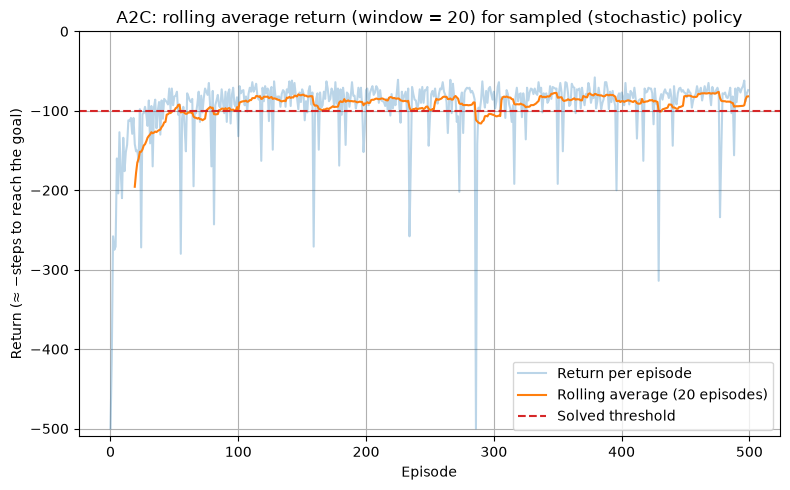

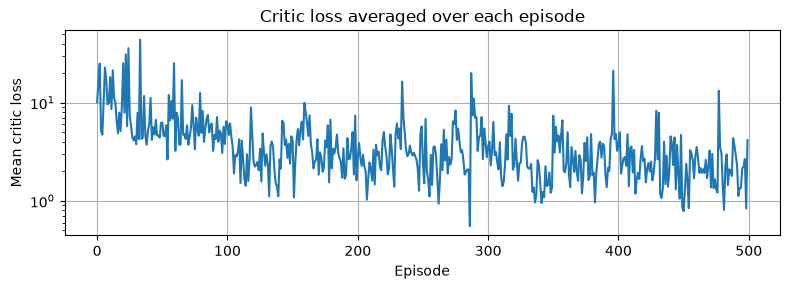

In [12]:
window = 20
rolling_rewards = np.convolve(
    np.array(rewards_all_episodes),
    np.ones(window) / window,
    mode="valid",
)

plt.figure(figsize=(8, 5))
plt.plot(rewards_all_episodes, alpha=0.3, label="Return per episode")
plt.plot(np.arange(window - 1, NUM_EPISODES), rolling_rewards, label=f"Rolling average ({window} episodes)")
plt.axhline(-100, color="tab:red", linestyle="--", label="Solved threshold")
plt.xlabel("Episode")
plt.ylabel("Return (≈ −steps to reach the goal)")
plt.ylim(-MAX_STEPS_PER_EPISODE - 10, 0)
plt.title(f"A2C: rolling average return (window = {window}) for sampled (stochastic) policy")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 3))
plt.plot(critic_losses)
plt.yscale("log")
plt.xlabel("Episode")
plt.ylabel("Mean critic loss")
plt.title("Critic loss averaged over each episode")
plt.grid(True)
plt.tight_layout()
plt.show()

## Evaluate the policy

Training samples actions from the policy, so its returns do not directly measure the greedy policy. We evaluate the trained actor over 100 fresh episodes in two ways, using the same 100 seeds:

1. choosing the **greedy** action;
2. **sampling** its actions, as during training.

If the two results are similar, the actor has become almost deterministic in the states it visits. Compare with the QAC notebook, where the last actor failed when it was greedy but worked when its actions were sampled.

In [13]:
def run_episode(choose_action, seed):
    """Run one episode with the given action rule and return its total reward."""
    state, info = env.reset(seed=seed)
    episode_return = 0.0

    for step in range(MAX_STEPS_PER_EPISODE):
        action = choose_action(state)
        state, reward, terminated, truncated, info = env.step(action)
        episode_return += reward

        if terminated or truncated:
            break

    return episode_return


def sample_action_no_grad(state):
    """Sample an action from the policy without building a graph (evaluation only)."""
    with torch.no_grad():
        action, log_probability = sample_action(state)

    return action

In [14]:
actor_net.eval()
greedy_returns = np.array(
    [run_episode(greedy_action, SEED + 1000 + i) for i in range(100)]
)
sampled_returns = np.array(
    [run_episode(sample_action_no_grad, SEED + 1000 + i) for i in range(100)]
)

for name, returns in [
    ("greedy ", greedy_returns),
    ("sampled", sampled_returns),
]:
    print(
        f"{name}: mean {returns.mean():7.1f} | std {returns.std():6.1f} | "
        f"min {returns.min():5.0f} | max {returns.max():5.0f} | "
        f"solved (mean >= -100): {returns.mean() >= -100}"
    )

greedy : mean   -81.4 | std    8.9 | min  -117 | max   -63 | solved (mean >= -100): True
sampled: mean   -88.8 | std   29.3 | min  -273 | max   -63 | solved (mean >= -100): True


## One greedy rollout

Instead of opening a separate rendering window, record one greedy episode and plot the height of the free end together with the applied torque. Since $\cos(\theta_1+\theta_2) = \cos\theta_1\cos\theta_2 - \sin\theta_1\sin\theta_2$, the height

$$h = -\cos\theta_1 - \cos(\theta_1 + \theta_2)$$

can be calculated directly from the observation. A successful policy alternates the torque to swing the links higher and higher until $h$ crosses the target line.

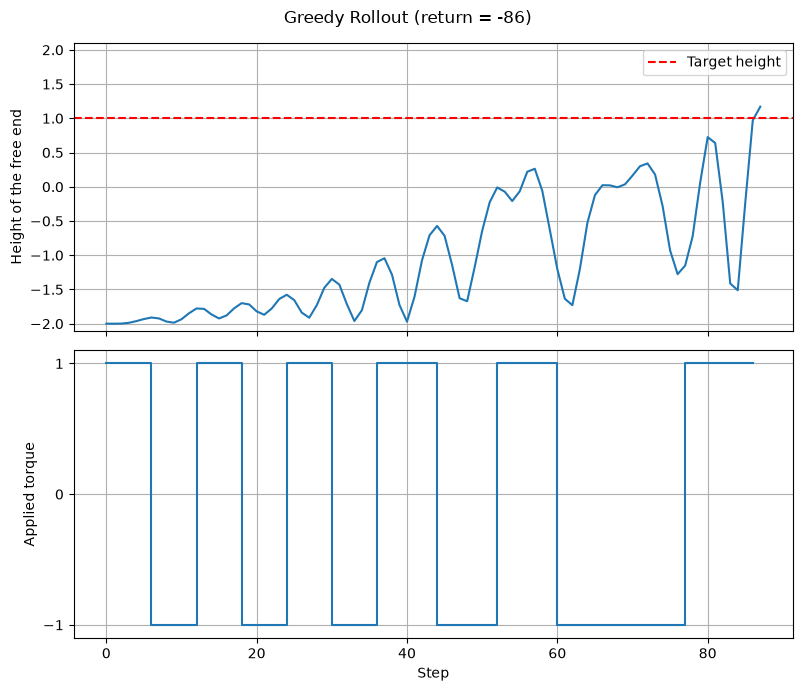

Rollout return: -86
Rollout steps:  87


In [15]:
state, info = env.reset(seed=SEED + 2000)
rollout_states = [state.copy()]
rollout_torques = []
rollout_return = 0.0

for step in range(MAX_STEPS_PER_EPISODE):
    action = greedy_action(state)
    state, reward, terminated, truncated, info = env.step(action)
    rollout_states.append(state.copy())
    rollout_torques.append(action - 1)  # actions 0, 1, 2 -> torque -1, 0, +1
    rollout_return += reward

    if terminated or truncated:
        break

rollout_states = np.array(rollout_states)
cos_1, sin_1 = rollout_states[:, 0], rollout_states[:, 1]
cos_2, sin_2 = rollout_states[:, 2], rollout_states[:, 3]
tip_height = -cos_1 - (cos_1 * cos_2 - sin_1 * sin_2)
time_steps = np.arange(len(rollout_states))

fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
axes[0].plot(time_steps, tip_height)
axes[0].axhline(1.0, color="red", linestyle="--", label="Target height")
axes[0].set_ylabel("Height of the free end")
axes[0].set_ylim(-2.1, 2.1)
axes[0].grid(True)
axes[0].legend()

axes[1].step(time_steps[:-1], rollout_torques, where="post")
axes[1].set_yticks([-1, 0, 1])
axes[1].set_xlabel("Step")
axes[1].set_ylabel("Applied torque")
axes[1].grid(True)

fig.suptitle(f"Greedy Rollout (return = {rollout_return:.0f})")
fig.tight_layout()
plt.show()

print(f"Rollout return: {rollout_return:.0f}")
print(f"Rollout steps:  {len(rollout_states) - 1}")

## Save the trained network

The learned policy is the actor, so we store the actor's state dictionary; the critic is only needed during training. The same `PolicyNetwork` architecture must be created before these weights are loaded later. We also check that the reloaded network chooses the same greedy action as the trained network.

To watch the saved actor, run from this folder:

```
python run_a2c_acrobot_policy.py --episodes 3
```

In [16]:
MODEL_PATH = "a2c_acrobot_policy.pth"
torch.save(actor_net.state_dict(), MODEL_PATH)

# Check that the saved state dictionary can be loaded.
saved_weights = torch.load(MODEL_PATH, map_location=device, weights_only=True)
check_net = PolicyNetwork(state_size, action_size, HIDDEN_SIZE).to(device)
check_net.load_state_dict(saved_weights)
check_net.eval()

check_state, info = env.reset(seed=SEED + 3000)
check_state_tensor = state_to_tensor(check_state)

with torch.no_grad():
    original_action = actor_net(check_state_tensor).argmax(dim=1).item()
    reloaded_action = check_net(check_state_tensor).argmax(dim=1).item()

print("Saved and reloaded:", MODEL_PATH)
print("Greedy actions match:", original_action == reloaded_action)
env.close()

Saved and reloaded: a2c_acrobot_policy.pth
Greedy actions match: True


## Compare with QAC

If `QAC_Acrobot_sol.ipynb` has been run, its training returns were saved in `qac_acrobot_returns.npy`. We compare the rolling averages of the two algorithms.

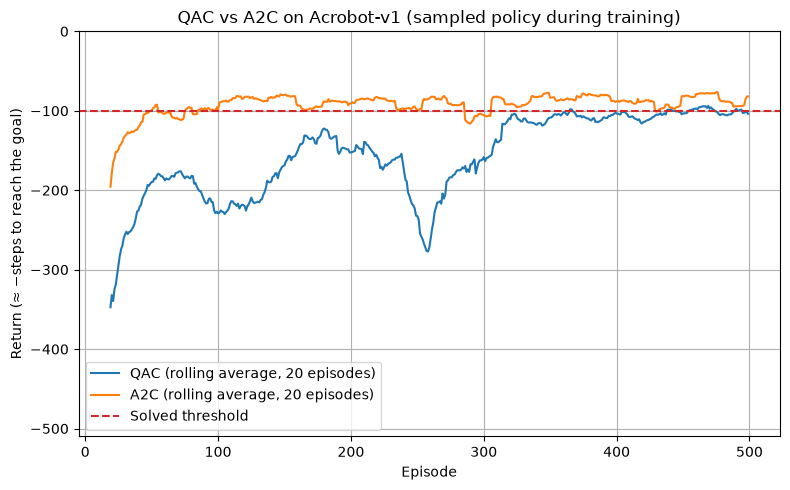

In [17]:
QAC_RETURNS_PATH = "qac_acrobot_returns.npy"

try:
    qac_returns = np.load(QAC_RETURNS_PATH)
except FileNotFoundError:
    qac_returns = None
    print(f"{QAC_RETURNS_PATH} not found: run QAC_Acrobot_sol.ipynb first.")

if qac_returns is not None:
    plt.figure(figsize=(8, 5))
    for name, returns in [("QAC", qac_returns), ("A2C", np.array(rewards_all_episodes))]:
        rolling = np.convolve(returns, np.ones(window) / window, mode="valid")
        plt.plot(np.arange(window - 1, len(returns)), rolling, label=f"{name} (rolling average, {window} episodes)")
    plt.axhline(-100, color="tab:red", linestyle="--", label="Solved threshold")
    plt.xlabel("Episode")
    plt.ylabel("Return (≈ -steps to reach the goal)")
    plt.ylim(-MAX_STEPS_PER_EPISODE - 10, 0)
    plt.title("QAC vs A2C on Acrobot-v1 (sampled policy during training)")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

## Remarks

* The only change from QAC to A2C is the weight of $\nabla_\theta \ln \pi(a_t \mid s_t;\theta)$: the action value $\hat q(s_t, a_t; w)$ is replaced by the TD error $\delta_t$, an estimate of the advantage. Since $\delta_t$ can be positive or negative, the actor makes good actions more likely and bad actions less likely, instead of decreasing every probability by a different amount.
* A2C needs a state-value critic $\hat v(s; w)$ only, which is easier to learn than $\hat q(s, a; w)$.
* Both QAC and A2C are **on-policy**: the samples must come from the current policy $\pi(\theta)$. Reusing old samples requires importance sampling (off-policy actor-critic).